# 03 - Model Karşılaştırma: Dummy vs Logistic Regression vs Random Forest

Aşama 3: aynı veri, aynı ayrım ve aynı test kümesiyle adil karşılaştırma.

## Kütüphaneler

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)

## Veri Setini Yükleme

In [2]:
# Notebook notebooks/ klasöründe çalışır; CSV UTF-8 BOM içerdiği için "utf-8-sig".
DATA_PATH = Path("../data/ai4i2020.csv")
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.shape

(10000, 14)

## Özellik ve Hedef Değişkenler

In [3]:
# Aşama 2 ile birebir aynı 6 özellik ve hedef.
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "Machine failure"

# Kimlikler ve arıza tipi etiketleri (arızadan sonra bilinir -> sızıntı) girdi olamaz.
EXCLUDED_COLUMNS = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df[FEATURES]
y = df[TARGET]

# Hedef ve yasaklı sütunlar X içinde olmamalı.
assert not (set(EXCLUDED_COLUMNS) | {TARGET}) & set(X.columns)
X.columns.tolist()

['Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]']

## Eğitim / Test Ayrımı

In [4]:
# Aşama 2 ile aynı ayrım: %80/%20, random_state=42, stratify=y.
# Tüm modeller bu tek X_test üzerinde değerlendirilecek; test kümesine eğitimde dokunulmaz.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "failures": [int(y_train.sum()), int(y_test.sum())],
    "failure rate": [round(y_train.mean(), 4), round(y_test.mean(), 4)],
}, index=["train", "test"])

,rows,failures,failure rate
train,8000,271,0.0339
test,2000,68,0.0340


## Model Pipeline'ları

In [5]:
# 1) Dummy: her zaman 'arıza yok' (0) der; alt sınır referansı.
dummy = DummyClassifier(strategy="constant", constant=0)

# 2) Logistic Regression: Aşama 2 ile birebir aynı yapı (ölçekleme + one-hot).
lr_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])),
    ("classifier", LogisticRegression(max_iter=1000)),
])

# 3) Random Forest: ağaçlar ölçeğe duyarsız olduğu için sayısal sütunlar olduğu gibi geçer;
# yalnızca Type one-hot kodlanır. Varsayılan ayarlar (100 ağaç), random_state=42.
rf_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])),
    ("classifier", RandomForestClassifier(random_state=42)),
])

models = {"Dummy (always 0)": dummy, "Logistic Regression": lr_model, "Random Forest": rf_model}

## Eğitim ve Tahmin

In [6]:
# Her model yalnızca eğitim verisiyle fit edilir ve aynı X_test üzerinde tahmin yapar.
# Varsayılan 0.5 eşiği kullanılır; eşik ayarı yapılmaz.
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

# Tüm tahminler aynı test kayıtları için (2000 satır) ve yalnızca 0/1 içermeli.
for name, y_pred in predictions.items():
    assert len(y_pred) == len(y_test)
    assert set(pd.unique(y_pred)) <= {0, 1}

pd.DataFrame({name: pd.Series(p).value_counts() for name, p in predictions.items()}).fillna(0).astype(int)

,Dummy (always 0),Logistic Regression,Random Forest
0,2000,1989,1962
1,0,11,38


## Performans Karşılaştırması

In [7]:
# Arıza sınıfı (1) için metrikler ve confusion matrix değerleri.
# zero_division=0: hiç '1' tahmini yoksa precision 0/0 olur; 0 kabul edilir.
rows = {}
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    rows[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }

comparison = pd.DataFrame(rows).T
comparison[["TP", "FP", "TN", "FN"]] = comparison[["TP", "FP", "TN", "FN"]].astype(int)
comparison.round(4)

,accuracy,precision,recall,f1,TP,FP,TN,FN
Dummy (always 0),0.9660,0.0000,0.0000,0.0000,0,0,1932,68
Logistic Regression,0.9675,0.6364,0.1029,0.1772,7,4,1928,61
Random Forest,0.9810,0.8947,0.5000,0.6415,34,4,1928,34


In [8]:
# Doğrulama: Logistic Regression sonuçları Aşama 2 raporuyla aynı olmalı.
STAGE2_REPORTED = {"TP": 7, "FP": 4, "TN": 1928, "FN": 61, "accuracy": 0.9675}

lr_row = comparison.loc["Logistic Regression"]
check = pd.DataFrame({
    "Stage 2 reported": STAGE2_REPORTED,
    "Stage 3 computed": {k: round(float(lr_row[k]), 4) for k in STAGE2_REPORTED},
})
check["match"] = check["Stage 2 reported"] == check["Stage 3 computed"]
assert check["match"].all(), "Logistic Regression sonuçları Aşama 2 ile uyuşmuyor!"
check

,Stage 2 reported,Stage 3 computed,match
TP,7.0000,7.0000,True
FP,4.0000,4.0000,True
TN,1928.0000,1928.0000,True
FN,61.0000,61.0000,True
accuracy,0.9675,0.9675,True


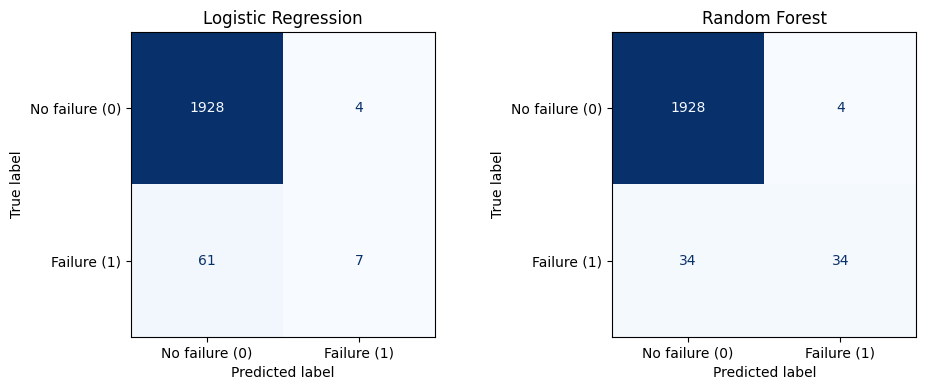

In [9]:
# Confusion matrix ısı haritaları: satır = gerçek sınıf, sütun = tahmin.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Logistic Regression", "Random Forest"]):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, predictions[name]),
        display_labels=["No failure (0)", "Failure (1)"],
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
fig.tight_layout()
plt.show()

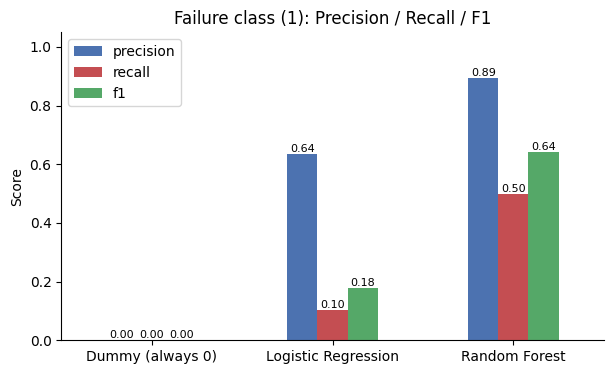

In [10]:
# Arıza sınıfı için Precision, Recall ve F1 karşılaştırması.
ax = comparison[["precision", "recall", "f1"]].astype(float).plot(
    kind="bar", figsize=(7, 4), rot=0, color=["#4C72B0", "#C44E52", "#55A868"]
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_title("Failure class (1): Precision / Recall / F1")
ax.set_ylabel("Score")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.show()

## Random Forest Özellik Önemi

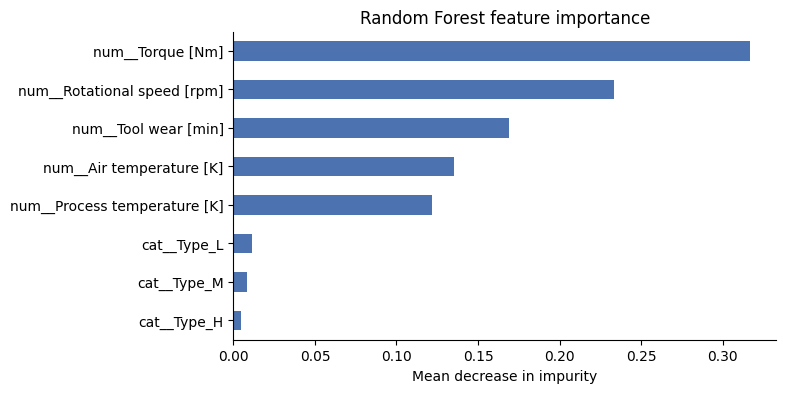

,importance
num__Torque [Nm],0.3169
num__Rotational speed [rpm],0.2333
num__Tool wear [min],0.1688
num__Air temperature [K],0.1353
num__Process temperature [K],0.1216
cat__Type_L,0.0111
cat__Type_M,0.0082
cat__Type_H,0.0048


In [11]:
# Feature importance: modelin karar verirken hangi özelliğe ne kadar DAYANDIĞINI gösterir.
# Nedensellik göstermez; "tork arızaya neden olur" sonucu buradan çıkarılamaz.
feature_names = rf_model.named_steps["preprocess"].get_feature_names_out()
importances = pd.Series(
    rf_model.named_steps["classifier"].feature_importances_, index=feature_names
).sort_values()

ax = importances.plot(kind="barh", figsize=(7, 4), color="#4C72B0")
ax.set_title("Random Forest feature importance")
ax.set_xlabel("Mean decrease in impurity")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importances.sort_values(ascending=False).round(4).to_frame("importance")